# Four sources, one wind farm: from raw data to a common model behind an OGC API
### Companion to the data-integration exercise (≈ 45 min)

The SES notebooks need one thing from the wind side: *which farms, how big, where, when*. Four public sources answer that question for the Polish Baltic, and they do not agree:

| Source | What it publishes | How we got it |
|---|---|---|
| **OpenStreetMap** | every turbine position with model, rotor and hub height; farm areas | API 0.6 `map` call, 27 Oct 2026 |
| **EMODnet Human Activities** | one point per farm or licence area; polygons for planning zones | WFS `emodnet:windfarms`, `emodnet:windfarmspoly`, 30 Oct 2026 |
| **HubOcean Ocean Data Platform (ODP)** | a copy of the EMODnet layers | public vector tiles (the table API needs an account), 30 Oct 2026 |
| **National reporting** | project list with capacity, status and first-power year, no coordinates | gramwzielone.pl, 26 Aug 2026 |

This notebook does three things:
1. **shows the differences** between the raw sources, value by value;
2. **translates each source into a common model** in three explicit steps — raw → the source's own semantics (its JSON-LD context, a published building block where one exists) → a common TBox (SPARQL CONSTRUCT) → a projection onto the target profile `emodnet-compliant-windfarm-pl`;
3. **puts both behind an OGC API – Features service** (pygeoapi): every raw source as it is, and harmonised collections that are translated *on request* from the raw files.

```
 raw file ──uplift──▶ source graph ──align──▶ common graph ──validate──▶ ──project──▶ GeoJSON / JSON-LD
 (as fetched)  context.jsonld       *.rq       + crosswalk     SHACL        policy       OGC API collections
```

| Time | Part |
|---|---|
| 0–5 min | 0. Setup and the raw files |
| 5–15 | 1. How the sources differ |
| 15–22 | 2. Uplift: each source in its own terms |
| 22–30 | 3. Align: one common TBox |
| 30–35 | 4. Validate |
| 35–40 | 5. Project onto the target profile |
| 40–45 | 6. Serve: OGC API – Features |

## 0. Setup
All pipeline code is in `windfarm_harmonise.py`; every decision lives in a configuration file under `config/multisource/` so it can be read, reviewed and changed without touching code:

| File | Decides |
|---|---|
| `sources.json` | the raw files, their JSON-LD contexts, IRI patterns, licences and alignment queries |
| `tbox/offshore-wind-common.ttl` | the common model: reuses the published EMODnet and Polish-profile terms, adds turbines and planning zones |
| `alignments/*.rq` | one SPARQL CONSTRUCT per source shape |
| `farm-crosswalk.json` (+ `../location-mapping.json`) | which records describe the same real-world farm |
| `shapes/*.shacl.ttl` | rules every translated record must satisfy |
| `projection.json` | which source wins for each property of the target profile |

In [1]:
import json, math, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import windfarm_harmonise as wh

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 70)

sources = wh.load_sources()
raw = {s["key"]: wh.read_raw(s) for s in sources}
pd.DataFrame([{"key": s["key"], "title": s["title"], "records": len(raw[s["key"]]["features"]),
               "geometry": ", ".join(sorted({(f["geometry"] or {"type": "none"})["type"] for f in raw[s["key"]]["features"]})),
               "snapshot": s["snapshot"], "licence": s["licence"]} for s in sources]).set_index("key")

,title,records,geometry,snapshot,licence
key,,,,,
national,"National project list (gramwzielone.pl, 26 Aug 2026)",9,none,2026-08-26,press report; facts compiled by the exercise
emodnet-wfs,"EMODnet Human Activities WFS emodnet:windfarms, Poland",26,Point,2026-10-30,EMODnet Open (attribution)
emodnet-wfs-zones,"EMODnet Human Activities WFS emodnet:windfarmspoly, Poland",7,MultiPolygon,2026-10-30,EMODnet Open (attribution)
odp-points,"HubOcean Ocean Data Platform: EMODnet wind farms (points), vector ...",13,Point,2026-10-30,EMODnet Open (attribution)
odp-zones,"HubOcean Ocean Data Platform: EMODnet wind farms (polygons), vecto...",7,MultiPolygon,2026-10-30,EMODnet Open (attribution)
osm,"OpenStreetMap, offshore Polish Baltic (API 0.6 map call)",292,"Point, Polygon, none",2026-10-27,"ODbL 1.0, © OpenStreetMap contributors"


The files in `../data/` are the responses exactly as received (checked byte for byte against the browser download with SHA-256). The ODP file is the only exception: vector tiles are binary, so it holds the decoded tile features, with coordinates converted from tile pixels to longitude and latitude.

## 1. How the sources differ (10 min)
### 1a. Different things on the map

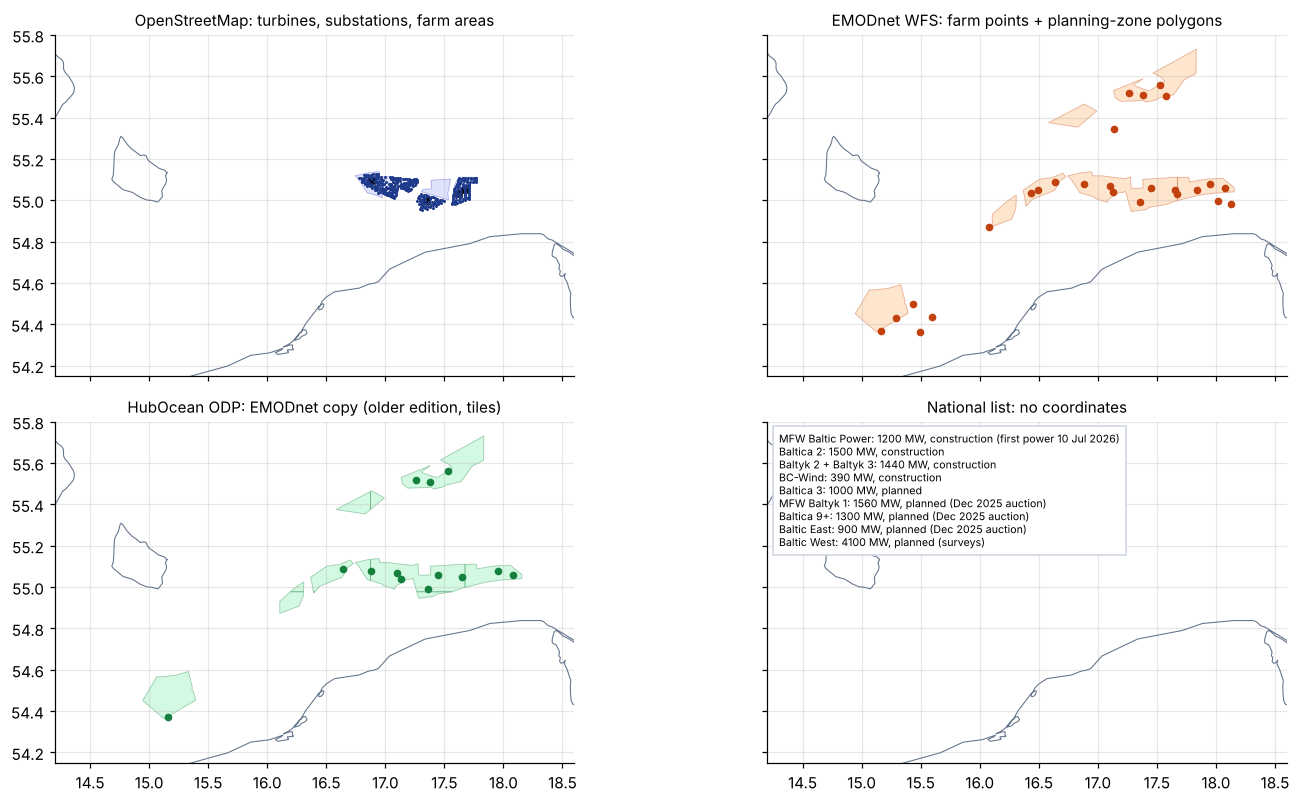

In [2]:
coast = json.load(open(wh.EXERCISE / "data/ne_10m_coastline_PL_Baltic.geojson"))
def draw_coast(ax):
    for f in coast["features"]:
        for line in f["geometry"]["coordinates"]:
            line = np.array(line); ax.plot(line[:, 0], line[:, 1], color="#64748b", lw=.7)

def fill(ax, geometry, **kw):
    for ring in wh.rings(geometry):
        ring = np.array(ring); ax.fill(ring[:, 0], ring[:, 1], **kw)

fig, axes = plt.subplots(2, 2, figsize=(14, 7.4), sharex=True, sharey=True)
panels = [("osm", "OpenStreetMap: turbines, substations, farm areas"), ("emodnet-wfs", "EMODnet WFS: farm points + planning-zone polygons"),
          ("odp-points", "HubOcean ODP: EMODnet copy (older edition, tiles)"), ("national", "National list: no coordinates")]
for ax, (key, title) in zip(axes.flat, panels):
    draw_coast(ax); ax.set_title(title, fontsize=10); ax.set_aspect(1.75)
    if key == "osm":
        for f in raw["osm"]["features"]:
            g, tags = f["geometry"], f["properties"]["tags"]
            if g and g["type"] == "Polygon": fill(ax, g, fc="#a5b4fc", alpha=.35, ec="#4338ca", lw=.6)
            elif g and tags.get("power") == "generator": ax.plot(*g["coordinates"], ".", color="#1e3a8a", ms=2)
            elif g and tags.get("power") == "substation": ax.plot(*g["coordinates"], "s", color="k", ms=4)
    if key == "emodnet-wfs":
        for f in raw["emodnet-wfs-zones"]["features"]: fill(ax, f["geometry"], fc="#fdba74", alpha=.35, ec="#c2410c", lw=.6)
        for f in raw["emodnet-wfs"]["features"]: ax.plot(*f["geometry"]["coordinates"], "o", color="#c2410c", ms=4)
    if key == "odp-points":
        for f in raw["odp-zones"]["features"]: fill(ax, f["geometry"], fc="#86efac", alpha=.35, ec="#15803d", lw=.6)
        for f in raw["odp-points"]["features"]: ax.plot(*f["geometry"]["coordinates"], "o", color="#15803d", ms=4)
    if key == "national":
        ax.text(14.3, 55.75, "\n".join(f'{r["properties"]["farm"]}: {r["properties"]["capacity_mw"]} MW, '
                                        f'{r["properties"]["status_aug2026"]}' for r in raw["national"]["features"]),
                fontsize=7, va="top", bbox=dict(fc="white", ec="#cbd5e1"))
    ax.set_xlim(14.2, 18.6); ax.set_ylim(54.15, 55.8)
plt.tight_layout(); plt.show()

Four sources, four *kinds* of thing: OSM describes **turbines** (283 of them) and **farm areas**; EMODnet describes **farms or licence areas as points** and **planning zones as polygons**; ODP republishes an **older edition** of EMODnet; the national list describes **projects** — commercial units that can span two sites (Bałtyk 2 + 3) or several licence areas (Baltic West) — without any location.

### 1b. The same farms, value by value
We link records only through the explicit crosswalk (part 3 explains it); here we simply read the raw values for the national projects.

In [3]:
mapping = json.loads((wh.ROOT / "config/location-mapping.json").read_text())["mappings"]
osm_rules = json.loads((wh.CONFIG / "farm-crosswalk.json").read_text())["osm"]
emodnet = {f["properties"]["name"]: f for f in raw["emodnet-wfs"]["features"]}
odp = {f["properties"]["name"]: f for f in raw["odp-points"]["features"]}
turbine_nodes = [f for f in raw["osm"]["features"] if f["properties"]["tags"].get("power") == "generator"]
relation_members = {m.split(":")[0] for f in raw["osm"]["features"] if f["properties"]["osm_type"] == "relation"
                    for m in f["properties"]["members"]}

def osm_turbines(project):
    rule = osm_rules.get(project, {}).get("turbines", {})
    keep = lambda t: (t["properties"]["tags"].get("model") == rule.get("model")
                      or any(t["properties"]["tags"].get("ref", "").startswith(p) for p in rule.get("ref_prefix", []))
                      or (rule.get("relation") and t["id"] in relation_members))
    return [t for t in turbine_nodes if rule and keep(t)]

def km(a, b):
    dx = (a[0] - b[0]) * 111.32 * math.cos(math.radians((a[1] + b[1]) / 2)); dy = (a[1] - b[1]) * 110.57
    return math.hypot(dx, dy)

rows = []
for f in raw["national"]["features"]:
    p = f["properties"]; names = mapping.get(p["farm"], [])
    e = [emodnet[n]["properties"] for n in names if n in emodnet]; o = [odp[n]["properties"] for n in names if n in odp]
    t = osm_turbines(p["farm"])
    centroid = tuple(np.mean([x["geometry"]["coordinates"] for x in t], axis=0)) if t else None
    e_pts = [emodnet[n]["geometry"]["coordinates"] for n in names if n in emodnet]
    rows.append({"project": p["farm"],
                 "MW national": float(p["capacity_mw"]), "MW EMODnet": sum(x["power_mw"] for x in e) if e else None,
                 "MW ODP": sum(x["power_mw"] for x in o) if o else None,
                 "MW OSM turbines": sum(float(x["properties"]["tags"].get("generator:output:electricity", "0 MW").split()[0]) for x in t) or None,
                 "turbines EMODnet": sum(x["n_turbines"] or 0 for x in e) or None, "turbines OSM": len(t) or None,
                 "status national": p["status_aug2026"], "status EMODnet": "/".join(sorted({x["status"] for x in e})) or None,
                 "status ODP": "/".join(sorted({x["status"] for x in o})) or None,
                 "year national": p["first_power_or_completion_year"], "year EMODnet": "/".join(sorted({str(x["year"]) for x in e})) or None,
                 "EMODnet point → OSM turbine centroid (km)": round(km(np.mean(e_pts, axis=0), centroid), 1) if (e_pts and centroid) else None})
compare = pd.DataFrame(rows).set_index("project")
compare

,MW national,MW EMODnet,MW ODP,MW OSM turbines,turbines EMODnet,turbines OSM,status national,status EMODnet,status ODP,year national,year EMODnet,EMODnet point → OSM turbine centroid (km)
project,,,,,,,,,,,,
MFW Baltic Power,1200.0,1140.0,1140.0,1140.0,76.0,76.0,construction (first power 10 Jul 2026),Construction,Construction,2026,2026,0.3
Baltica 2,1500.0,1498.0,1498.0,1498.0,NaN,107.0,construction,Planned,Planned,2027,2027,0.2
Baltyk 2 + Baltyk 3,1440.0,1440.0,1440.0,NaN,NaN,100.0,construction,Planned,Planned,2028,2028,0.7
BC-Wind,390.0,500.0,NaN,NaN,NaN,NaN,construction,Planned,NaN,2028,2028,NaN
Baltica 3,1000.0,1045.5,1045.5,NaN,NaN,NaN,planned,Planned,Planned,2030,2030,NaN
MFW Baltyk 1,1560.0,1560.0,1560.0,NaN,260.0,NaN,planned (Dec 2025 auction),Planned,Planned,2032,2028,NaN
Baltica 9+,1300.0,1325.0,350.0,NaN,NaN,NaN,planned (Dec 2025 auction),Planned,Planned,2032,2030/None,NaN
Baltic East,900.0,966.0,NaN,NaN,NaN,NaN,planned (Dec 2025 auction),Planned,NaN,2032,None,NaN
Baltic West,4100.0,NaN,NaN,NaN,NaN,NaN,planned (surveys),NaN,NaN,2035,NaN,NaN


> **Read the table.** Nothing here is an error by itself; each source answers a slightly different question.
> * **Capacity.** Baltic Power: 1200 MW nationally, 1140 MW in EMODnet and in the 76 × 15 MW turbines mapped in OSM. Baltica 9+ is 1300 MW nationally, 1325 MW as two EMODnet sites, but only 350 MW in ODP — whose older edition lacks Baltica 9. BC-Wind: 390 MW vs 500 MW (two EMODnet licence areas).
> * **Status.** Bałtyk 2 + 3 and Baltica 2 are under construction nationally and in OSM, but *Planned* in EMODnet: status ages faster than an annual update.
> * **Year.** Bałtyk 1 first power: 2032 nationally (after the Dec 2025 auction), 2028 in EMODnet.
> * **Location.** EMODnet places each farm with one point rounded to 0.01°. For the farms under construction it lies only 0.2–0.7 km from the centroid of the mapped turbines — but one point cannot describe a farm of 100–200 km² for wake, fishing-displacement or habitat-overlap analysis.
> * **Unit of record.** One national project = two EMODnet points (Bałtyk 2 + 3, BC-Wind, Baltica 9+, Bałtyk 1); Baltic West has no EMODnet counterpart at all.

### 1c. EMODnet and its copy on ODP

In [4]:
rows = []
for name, f in emodnet.items():
    o = odp.get(name)
    rows.append({"name": name, "in ODP": o is not None,
                 "updateyear WFS": f["properties"]["updateyear"], "updateyear ODP": o["properties"].get("updateyear") if o else None,
                 "MW WFS": f["properties"]["power_mw"], "MW ODP": o["properties"]["power_mw"] if o else None,
                 "offset (m)": round(km(f["geometry"]["coordinates"], o["geometry"]["coordinates"]) * 1000) if o else None})
edition = pd.DataFrame(rows).set_index("name")
print(f"ODP has {edition['in ODP'].sum()} of the {len(edition)} Polish EMODnet records; "
      f"fields only in the WFS: {sorted(set(next(iter(emodnet.values()))['properties']) - set(next(iter(odp.values()))['properties']))}")
edition.sort_values("in ODP")

ODP has 13 of the 26 Polish EMODnet records; fields only in the WFS: ['notes', 'type_inst', 'year']


,in ODP,updateyear WFS,updateyear ODP,MW WFS,MW ODP,offset (m)
name,,,,,,
Baltic East,False,2026,NaN,966.0,NaN,NaN
Energa MFW 1 Offshore wind farm 1,False,2026,NaN,900.0,NaN,NaN
Freeboard I Offshore wind farm 1,False,2026,NaN,1500.0,NaN,NaN
Orlen Neptun IV Offshore wind farm 1,False,2026,NaN,1200.0,NaN,NaN
Baltica V Offshore wind farm 1,False,2026,NaN,555.0,NaN,NaN
Orlen Neptun III Offshore wind farm 1,False,2026,NaN,1200.0,NaN,NaN
Energa MFW 2 Offshore wind farm 1,False,2026,NaN,800.0,NaN,NaN
Baltica IV Offshore wind farm 1,False,2026,NaN,990.0,NaN,NaN
Orlen Neptun VIII Offshore wind farm 1,False,2026,NaN,1000.0,NaN,NaN


> The ODP copy is an **earlier edition** (`updateyear` 2024–2025, 13 Polish records) with the year, installation type and notes fields dropped; its coordinates are shifted by a few metres because vector tiles quantise them to a 4096-pixel grid per tile, and its polygons are cut at tile edges. A copy is a new dataset with its own edition and processing history — a twin must know which one it read.

## 2. Uplift: each source in its own terms (7 min)
The first step changes no value. Each raw feature gets a global identifier and is read with **its source's own JSON-LD context**. For EMODnet and the national list these contexts are the published SeaDOTs building blocks `emodnet-compliant-windfarm` and `national-windfarm-source`; for ODP we reuse the EMODnet block (it is EMODnet data); OSM gets a context that maps tag keys to their wiki definitions. Geometry is carried as GeoSPARQL WKT.

In [5]:
raw_graphs = {s["key"]: wh.uplift(s, raw[s["key"]]) for s in sources}
display(pd.DataFrame([{"source": s["key"], "context(s)": ", ".join(s["contexts"]), "IRI pattern": s["id_template"][:80],
                       "triples": len(raw_graphs[s["key"]])} for s in sources]).set_index("source"))

def turtle_of(graph, subject):
    sub = __import__("rdflib").Graph()
    for prefix, ns in wh.NS.items(): sub.bind(prefix, ns)
    sub.bind("osmk", "https://wiki.openstreetmap.org/wiki/Key:"); sub.bind("geojson", "https://purl.org/geojson/vocab#")
    sub.bind("nws", "https://w3id.org/ogc/hosted/seadots/national-windfarm-source#")
    todo, seen = [__import__("rdflib").URIRef(subject)], set()
    while todo:
        s = todo.pop()
        if s in seen: continue
        seen.add(s)
        for p, o in graph.predicate_objects(s):
            sub.add((s, p, o))
            if isinstance(o, __import__("rdflib").BNode): todo.append(o)
    return sub.serialize(format="turtle")

print(turtle_of(raw_graphs["osm"], "https://www.openstreetmap.org/node/14185128570"))
print(turtle_of(raw_graphs["odp-points"], "https://app.hubocean.earth/catalog/dataset/421294d9-696e-47a8-9f23-0473d726abab#baltic-power"))

,context(s),IRI pattern,triples
source,,,
national,bblock:national-windfarm-source,urn:baltic-ses:national:{slug},72
emodnet-wfs,"bblock:emodnet-compliant-windfarm, geometry-wkt.jsonld",https://ows.emodnet-humanactivities.eu/wfs?service=WFS&version=2.0...,295
emodnet-wfs-zones,"bblock:emodnet-compliant-windfarm, geometry-wkt.jsonld",https://ows.emodnet-humanactivities.eu/wfs?service=WFS&version=2.0...,82
odp-points,"bblock:emodnet-compliant-windfarm, geometry-wkt.jsonld",https://app.hubocean.earth/catalog/dataset/421294d9-696e-47a8-9f23...,133
odp-zones,"bblock:emodnet-compliant-windfarm, geometry-wkt.jsonld",https://app.hubocean.earth/catalog/dataset/8dbcac0b-bdce-4714-ab02...,93
osm,"osm-raw.jsonld, geometry-wkt.jsonld",https://www.openstreetmap.org/{id},4805


@prefix geo: <http://www.opengis.net/ont/geosparql#> .
@prefix geojson: <https://purl.org/geojson/vocab#> .
@prefix ns1: <https://wiki.openstreetmap.org/wiki/Key:generator:> .
@prefix ns2: <https://wiki.openstreetmap.org/wiki/Key:generator:output:> .
@prefix ns3: <https://wiki.openstreetmap.org/wiki/Key:height:> .
@prefix ns4: <https://wiki.openstreetmap.org/wiki/Key:rotor:> .
@prefix osmk: <https://wiki.openstreetmap.org/wiki/Key:> .
@prefix osmr: <urn:baltic-ses:osm-raw#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<https://www.openstreetmap.org/node/14185128570> a geojson:Feature ;
    geo:hasGeometry [ geo:asWKT "POINT (17.66812 55.10027)"^^geo:wktLiteral ] ;
    geojson:properties [ ns1:method "wind_turbine" ;
            ns2:electricity "15 MW" ;
            ns1:source "wind" ;
            ns1:type "horizontal_axis" ;
            ns3:hub "141" ;
            osmk:manufacturer "Vestas" ;
            osmk:model "V236-15.0 MW" ;
            osmk:offshore "yes" ;
           

The OSM turbine keeps OSM's own words (`osmk:generator:output:electricity "15 MW"` — a string with a unit inside). The ODP record already speaks the EMODnet block's vocabulary (`em:powerMW`, the status as a `sem:` concept) because we read it with that block's context: **the building block does the first half of the harmonisation for free.**

## 3. Align: one common TBox (8 min)
The common model (`tbox/offshore-wind-common.ttl`) reuses every term the blocks already define — `em:powerMW`, `em:nTurbines`, `em:year`, the `sem:` status concepts, the `ses:` provenance terms — and adds only what no block has yet: turbines (`owc:WindTurbine`, `owc:ratedPowerMW`, `owc:hubHeightM`, …), planning zones, and **source records**.

A *source record* is what one dataset says about one farm. Records from different sources are kept side by side and linked to the real-world farm with `owc:describes`; nothing is overwritten. One CONSTRUCT query per source *shape* does the translation — the same `emodnet-points.rq` serves the WFS and the ODP copy:

In [6]:
print((wh.CONFIG / "alignments/emodnet-points.rq").read_text())

# EMODnet wind-farm points (emodnet-compliant-windfarm block) -> common records.
# Used unchanged for the EMODnet WFS and for the HubOcean ODP copy: both carry the EMODnet schema.
CONSTRUCT {
  ?rec a owc:SourceRecord ; owc:recordKind owc:WindFarm ; owc:sourceKey ?key ;
       schema:name ?name ; em:powerMW ?mw ; em:nTurbines ?n ; owc:status ?status ; owc:sourceStatusText ?statusText ;
       em:year ?year ; em:updateYear ?updateyear ; em:distanceToCoast ?dist ; schema:additionalType ?inst ;
       owc:locationKind "point" ; geo:hasGeometry ?geom ;
       dcterms:source ?dataset ; ses:sourceSnapshotDate ?snapshot ; prov:wasDerivedFrom ?f .
  ?geom geo:asWKT ?wkt .
}
WHERE {
  ?f geojson:properties ?p ; geo:hasGeometry ?geom . ?geom geo:asWKT ?wkt .
  ?p sem:name ?name .
  OPTIONAL { ?p em:powerMW ?mw0 } OPTIONAL { ?p em:nTurbines ?n0 }
  OPTIONAL { ?p sem: ?status . BIND(STRAFTER(STR(?status), STR(sem:)) AS ?statusText) }
  OPTIONAL { ?p em:year ?year } OPTIONAL { ?p em:updateYear ?upd

In [7]:
crosswalk = wh.crosswalk_graph(raw)
common, added = wh.align(sources, raw_graphs, crosswalk)
zone_links = wh.add_zone_links(common, raw)
print("triples added per source:", added, "| farm-in-zone links:", zone_links, "| common graph:", len(common), "triples")

q = '''SELECT ?source ?name ?mw ?n ?status ?year ?location WHERE {
         ?r owc:describes <urn:baltic-ses:farm:mfw-baltic-power> ; owc:sourceKey ?k ; owc:locationKind ?location .
         BIND(STRBEFORE(?k, "|") AS ?source)
         OPTIONAL { ?r schema:name ?name } OPTIONAL { ?r em:powerMW ?mw } OPTIONAL { ?r em:nTurbines ?n }
         OPTIONAL { ?r owc:status ?st BIND(STRAFTER(STR(?st), STR(sem:)) AS ?status) } OPTIONAL { ?r em:year ?year } }
       ORDER BY ?source'''
display(pd.DataFrame([{k: (None if r[k] is None else str(r[k])) for k in r.labels} for r in common.query(q, initNs=wh.NS)]))
q2 = '''SELECT ?model (COUNT(?t) AS ?turbines) (SAMPLE(?rotor) AS ?rotor_m) (SAMPLE(?hub) AS ?hub_m) (SAMPLE(?rated) AS ?rated_mw) WHERE {
          ?t owc:partOfFarm ?farm ; owc:turbineModel ?model .
          OPTIONAL { ?t owc:rotorDiameterM ?rotor } OPTIONAL { ?t owc:hubHeightM ?hub } OPTIONAL { ?t owc:ratedPowerMW ?rated } }
        GROUP BY ?model'''
pd.DataFrame([{k: (None if r[k] is None else str(r[k])) for k in r.labels} for r in common.query(q2, initNs=wh.NS)])

triples added per source: {'national': 135, 'emodnet-wfs': 425, 'emodnet-wfs-zones': 95, 'odp-points': 198, 'odp-zones': 95, 'osm': 3455} | farm-in-zone links: 15 | common graph: 4912 triples


,source,name,mw,n,status,year,location
0,emodnet-wfs,Baltic Power,1140.0,76,Construction,2026,point
1,national,MFW Baltic Power,1200,NaN,Construction,2026,none
2,odp-points,Baltic Power,1140,76,Construction,NaN,point
3,osm,Baltic Power,1200,NaN,NaN,NaN,none
4,osm,Baltic Power,NaN,NaN,NaN,NaN,area


,model,turbines,rotor_m,hub_m,rated_mw
0,SG 14-236 DD,100,236,NaN,NaN
1,SG 14-222 DD,107,222,NaN,14
2,V236-15.0 MW,76,236,141,15


**The crosswalk** is the one place where a human decides that two records are the same farm. National ↔ EMODnet links come from the existing `location-mapping.json`; ODP records are linked by their identical EMODnet name; OSM elements are declared by id, and OSM turbines by a rule — membership of the Baltic Power relation, the model `SG 14-222 DD` for Baltica 2, the `ref` prefixes `BK2`/`BK3` for Bałtyk. Planning zones are linked spatially: a farm is *within* a zone if its reference point is inside the zone polygon.

> **Watch out for identifiers.** A first version of the crosswalk made farm IRIs from slugs of names: "Baltica 2" and "Baltica 2+" both became `baltica-2`, silently merging two EMODnet records into one 1708 MW farm. SHACL caught it as a capacity disagreement. Identifiers are design decisions, not formatting.

## 4. Validate (5 min)
SHACL shapes check every translated record regardless of its source: identifiers and provenance present, capacity a positive number of MW below 6 GW (catches unit errors such as EMODnet's 1000× Bockstigen value in Sweden), status from the EMODnet vocabulary, each turbine in exactly one farm. Two SPARQL-based shapes compare sources: capacity disagreement above 5 % and reported vs mapped turbine numbers are reported as **warnings** — the projection may still pick a value, but a reader must be able to see that sources differ.

In [8]:
conforms, results = wh.validate(common)
report = pd.DataFrame(results)
print("conforms (no violations):", conforms)
display(report.groupby(["severity", "message"]).size().rename("count").reset_index())
report[report.severity == "Warning"].assign(focus=lambda d: d.focus.str.split(":").str[-1])[["focus", "message"]]

conforms (no violations): True


,severity,message,count
0,Info,No status that maps to the EMODnet vocabulary.,3
1,Info,Turbine has no hub height in the source.,207
2,Info,Turbine has no rated power in the source; it must come from the tu...,100
3,Warning,"Reported number of turbines (50, osm) differs from turbines mapped...",1
4,Warning,Sources disagree on capacity by more than 5 %: 1140 MW (odp-points...,1
5,Warning,Sources disagree on capacity by more than 5 %: 1140 MW (odp-points...,1
6,Warning,Sources disagree on capacity by more than 5 %: 1140.0 MW (emodnet-...,1
7,Warning,Sources disagree on capacity by more than 5 %: 1140.0 MW (emodnet-...,1
8,Warning,Sources disagree on capacity by more than 5 %: 350 MW (odp-points)...,1
9,Warning,Sources disagree on capacity by more than 5 %: 350 MW (odp-points)...,1


,focus,message
310,baltic-east,Sources disagree on capacity by more than 5 %: 900 MW (national) v...
311,baltica-9-plus,Sources disagree on capacity by more than 5 %: 350 MW (odp-points)...
312,baltica-9-plus,Sources disagree on capacity by more than 5 %: 350 MW (odp-points)...
313,baltyk-2-plus-baltyk-3,"Reported number of turbines (50, osm) differs from turbines mapped..."
314,baltyk-2-plus-baltyk-3,Sources disagree on capacity by more than 5 %: 720 MW (osm) vs 144...
315,baltyk-2-plus-baltyk-3,Sources disagree on capacity by more than 5 %: 720 MW (osm) vs 144...
316,baltyk-2-plus-baltyk-3,Sources disagree on capacity by more than 5 %: 720 MW (osm) vs 144...
317,bc-wind,Sources disagree on capacity by more than 5 %: 390 MW (national) v...
318,mfw-baltic-power,Sources disagree on capacity by more than 5 %: 1140 MW (odp-points...
319,mfw-baltic-power,Sources disagree on capacity by more than 5 %: 1140 MW (odp-points...


> **Read the warnings.** Most are the disagreements seen in part 1. Two are new and only visible after linking: OSM's *MFW Bałtyk II* area says 720 MW and 50 turbines, while the national project *Bałtyk 2 + 3* is 1440 MW with 100 mapped turbines. Both are right — the OSM area is **part of** the project, not the same thing. The crosswalk has only one kind of link (`owc:describes`); a production model would also need *part of*, so that a projection can sum parts instead of comparing them. The validation found a modelling gap, not a data error.

## 5. Project onto the target profile (5 min)
The **projection policy** (`projection.json`) says, for each property of `emodnet-compliant-windfarm-pl`, which source wins: the national list for capacity, status and year (newest, project-level), OSM for the number of turbines and the location (counted and measured, not reported), EMODnet for distance to coast and installation type. The result is checked against the published JSON Schema of the block. Because that profile allows only one `source_type` per record, the values taken from other sources are listed in `notes`; the `farms-common` collection keeps every record and the source of every chosen value.

In [9]:
collections = wh.project(common, raw, sources)
errors = wh.validate_target_profile(collections["farms-pl"])
print("farms valid against emodnet-compliant-windfarm-pl:", sum(not e for e in errors.values()), "of", len(errors))
farms_pl = pd.DataFrame([{**f["properties"], "lon": (f["geometry"] or {"coordinates": [None]})["coordinates"][0]}
                         for f in collections["farms-pl"]["features"]])
farms_pl[["name", "power_mw", "n_turbines", "status", "year", "source_type", "location_status", "location_method", "notes"]]

farms valid against emodnet-compliant-windfarm-pl: 23 of 23


,name,power_mw,n_turbines,status,year,source_type,location_status,location_method,notes
0,B-Wind,200.0,NaN,Planned,NaN,emodnet,source-provided,emodnet-wfs point(s),NaN
1,BC-Wind,390.0,NaN,Construction,2028,national,mapped,emodnet-wfs (centroid of 2 points) point(s),values merged from several sources: updateyear from emodnet-wfs; d...
2,Baltic East,900.0,NaN,Planned,2032,national,mapped,emodnet-wfs point(s),values merged from several sources: updateyear from emodnet-wfs; d...
3,Baltic West,4100.0,NaN,Planned,2035,national,anticipated,Approximate representative point inferred from ORLEN Neptun's desc...,values merged from several sources: geometry from anticipated (loc...
4,Baltica 1,900.0,NaN,Planned,2030,emodnet,source-provided,emodnet-wfs point(s),NaN
5,Baltica 2,1500.0,107.0,Construction,2027,national,mapped,centroid of 107 OpenStreetMap turbine positions,values merged from several sources: n_turbines from osm-count; upd...
6,Baltica 2+,210.0,NaN,Planned,NaN,emodnet,source-provided,emodnet-wfs point(s),NaN
7,Baltica 3,1000.0,NaN,Planned,2030,national,mapped,emodnet-wfs point(s),values merged from several sources: updateyear from emodnet-wfs; d...
8,Baltica 9+,1300.0,NaN,Planned,2032,national,mapped,emodnet-wfs (centroid of 2 points) point(s),values merged from several sources: updateyear from emodnet-wfs; d...
9,Baltica IV Offshore wind farm 1,990.0,NaN,Planned,NaN,emodnet,source-provided,emodnet-wfs point(s),NaN


In [10]:
choice = pd.DataFrame({f["properties"]["name"]: f["properties"]["value_sources"] for f in collections["farms-common"]["features"]}).T
choice = choice[["power_mw", "n_turbines", "status", "year", "geometry"]]
choice.loc[compare.index.intersection(choice.index)].fillna("—")

,power_mw,n_turbines,status,year,geometry
MFW Baltic Power,national,osm-count,national,national,osm-turbine-centroid
Baltica 2,national,osm-count,national,national,osm-turbine-centroid
Baltyk 2 + Baltyk 3,national,osm-count,national,national,osm-turbine-centroid
BC-Wind,national,—,national,national,emodnet-wfs (centroid of 2 points)
Baltica 3,national,—,national,national,emodnet-wfs
MFW Baltyk 1,national,emodnet-wfs,national,national,emodnet-wfs (centroid of 2 points)
Baltica 9+,national,—,national,national,emodnet-wfs (centroid of 2 points)
Baltic East,national,—,national,national,emodnet-wfs
Baltic West,national,—,national,national,anticipated (location-mapping.json)


## 6. Serve: OGC API – Features (5 min)
`write_service` generates a pygeoapi configuration with ten collections:
* six **raw** collections — `raw-osm`, `raw-emodnet-points`, `raw-emodnet-zones`, `raw-odp-points`, `raw-odp-zones`, `raw-national` — served exactly as received; with `f=jsonld` they carry their source context, i.e. the uplift step;
* four **harmonised** collections — `farms-pl` (the target profile), `farms-common`, `turbines`, `zones` — served by `windfarm_harmonise.HarmonisedProvider`, which runs uplift → align → project on the raw files when a request arrives and caches the result until a raw file or a configuration file changes. Change `projection.json`, and the next request reflects it. Unlike pygeoapi's built-in GeoJSON provider it also honours `bbox`.

The service uses the same isolated environment as the first data-integration exercise (`./setup_pygeoapi.sh`; it now also installs `rdflib`) and listens on port 5001, so both services can run side by side.

In [11]:
SERVICE = wh.ROOT / "service-multisource"
result = {"sources": sources, "raw": raw, "collections": collections}
resources = wh.write_service(SERVICE, result, port=5001)
print("collections:", list(resources))

PYGEOAPI = os.environ.get("PYGEOAPI", str(wh.ROOT / ".venv/bin/pygeoapi"))
BASE = "http://localhost:5001"
server = None
if Path(PYGEOAPI).exists():
    server = subprocess.Popen(["sh", str(SERVICE / "run.sh")], env={**os.environ, "PYGEOAPI": PYGEOAPI},
                              stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    import urllib.request
    for _ in range(60):
        try:
            urllib.request.urlopen(BASE + "/?f=json", timeout=2); break
        except Exception:
            time.sleep(1)
    print("pygeoapi running at", BASE)
else:
    print("pygeoapi not installed: run ./setup_pygeoapi.sh, then ./service-multisource/run.sh")

collections: ['raw-national', 'raw-emodnet-points', 'raw-emodnet-zones', 'raw-odp-points', 'raw-odp-zones', 'raw-osm', 'farms-pl', 'farms-common', 'turbines', 'zones']


pygeoapi running at http://localhost:5001


In [12]:
import urllib.request
def get(path):
    with urllib.request.urlopen(BASE + path, timeout=60) as r:
        return json.loads(r.read())

if server:
    print([c["id"] for c in get("/collections?f=json")["collections"]])
    bp = "/items?f=json&bbox=17.55,54.97,17.80,55.12&limit=500"
    print("turbines in the Baltic Power bbox:", get("/collections/turbines" + bp)["numberMatched"])
    print("raw OSM features in the same bbox (built-in GeoJSON provider ignores bbox):", get("/collections/raw-osm" + bp)["numberMatched"])
    raw_item = get("/collections/raw-emodnet-points/items/windfarms.268?f=json")["properties"]
    harmonised = get("/collections/farms-pl/items/mfw-baltic-power?f=json")["properties"]
    display(pd.DataFrame({"raw-emodnet-points": pd.Series(raw_item), "farms-pl": pd.Series(harmonised)}).fillna("—"))
    ld = get("/collections/farms-pl/items/mfw-baltic-power?f=jsonld")
    print(json.dumps({k: ld[k] for k in ld if k != "@context"}, indent=1, ensure_ascii=False)[:1200])

['raw-national', 'raw-emodnet-points', 'raw-emodnet-zones', 'raw-odp-points', 'raw-odp-zones', 'raw-osm', 'farms-pl', 'farms-common', 'turbines', 'zones']


turbines in the Baltic Power bbox: 76
raw OSM features in the same bbox (built-in GeoJSON provider ignores bbox): 292


,raw-emodnet-points,farms-pl
country,Poland,Poland
developer,—,Orlen; Northland Power
dist_coast,28426.906965,28426.906965
location_emodnet_ids,—,[https://ows.emodnet-humanactivities.eu/wfs?service=WFS&version=2....
location_method,—,centroid of 76 OpenStreetMap turbine positions
location_reference,—,https://www.openstreetmap.org/relation/21402440
location_status,—,mapped
n_turbines,76,76
name,Baltic Power,MFW Baltic Power
notes,—,values merged from several sources: n_turbines from osm-count; upd...


{
 "type": "schema:Place",
 "id": "urn:baltic-ses:farm:mfw-baltic-power",
 "name": "MFW Baltic Power",
 "country": "Poland",
 "n_turbines": 76,
 "power_mw": 1200.0,
 "status": "Construction",
 "type_inst": "Grounded",
 "updateyear": "2026",
 "year": "2026",
 "dist_coast": 28426.9069649,
 "notes": "values merged from several sources: n_turbines from osm-count; updateyear from emodnet-wfs; dist_coast from emodnet-wfs; type_inst from emodnet-wfs; geometry from osm-turbine-centroid",
 "developer": "Orlen; Northland Power",
 "status_detail": "construction (first power 10 Jul 2026)",
 "status_as_of": "2026-08-26",
 "year_semantics": "planned first-power or completion year",
 "year_is_assumed": false,
 "source_type": "national",
 "source_dataset": "National project list (gramwzielone.pl, 26 Aug 2026)",
 "source_reference": "https://www.gramwzielone.pl/?p=20373718",
 "source_snapshot_date": "2026-08-26",
 "source_record_id": "MFW Baltic Power",
 "location_status": "mapped",
 "location_method":

In [13]:
if server:
    server.terminate(); server.wait(timeout=10)
    print("service stopped; start it again with ./service-multisource/run.sh")

service stopped; start it again with ./service-multisource/run.sh


## Your turn
1. **Change the policy.** In `config/multisource/projection.json` put `emodnet-wfs` before `national` for `power_mw`. Restart the service (or re-run part 5). Which farms change? Which of the two answers would you give the SES model, and why?
2. **Extend the crosswalk.** OSM maps the Baltica 3 area but no turbines yet. Add a turbine rule for it once they appear, and decide which model value the rule should match.
3. **A new source.** HELCOM's maritime-spatial-planning layer has 13 Polish "Offshore wind farms" polygons. Add it to `sources.json` with the EMODnet zone query. What did you have to write — a context, a query, crosswalk entries — and what did you reuse?
4. **Tighten a rule.** Turn the capacity-agreement shape into a violation (`sh:Violation`). Which farms would now block a release, and is that what you want for a twin that updates nightly?

## What this companion shows — and what it still assumes
| | Status |
|---|---|
| Raw values, geometries, identifiers | **DATA**, as fetched; ODP decoded from vector tiles |
| Source semantics | published building-block contexts (EMODnet, national); exercise contexts for OSM and geometry |
| Common TBox | reuses `em:`, `sem:`, `ses:`; the `owc:` terms are local to the exercise — a candidate for a turbine-level building block |
| Same-farm links | **ASSUMPTION**, explicit in the crosswalk files; zone membership by a point-in-polygon rule |
| Which value wins | **POLICY**, explicit in `projection.json`; every choice is reported in `farms-common` |
| Not covered | substations (in OSM and the raw graph, not yet in the common model), HELCOM MSP layer, temporal versioning of editions |

### Sources
* OpenStreetMap contributors, © ODbL 1.0: https://www.openstreetmap.org/copyright
* EMODnet Human Activities, wind farms: https://emodnet.ec.europa.eu/en/human-activities — WFS https://ows.emodnet-humanactivities.eu/wfs
* HubOcean Ocean Data Platform catalogue: https://app.hubocean.earth (datasets 421294d9-696e-47a8-9f23-0473d726abab and 8dbcac0b-bdce-4714-ab02-f2aee6c28e85)
* National project list: gramwzielone.pl, 26 Aug 2026 — https://www.gramwzielone.pl/?p=20373718
* SeaDOTs building blocks: https://ogcincubator.github.io/bblocks-seadots/ — pygeoapi: https://pygeoapi.io